<a href="https://colab.research.google.com/github/JayDeRukz/Bank_Customer_Churn_Prediction/blob/main/Bank_Customer_Churn_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")
print("Project: Bank Customer Churn Prediction")

Libraries imported successfully!
Project: Bank Customer Churn Prediction


In [ ]:

from google.colab import files

uploaded = files.upload()

# Load the CSV file
df = pd.read_csv('Churn_Modelling.csv')

# Display first five records
df.head()

Saving Churn_Modelling.csv to Churn_Modelling.csv


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [ ]:

# Check dataset dimensions

print("Dataset shape:", df.shape)

# Check column information

df.info()

# Check missing values

print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records

print("\nDuplicate records:", df.duplicated().sum())

# Check target distribution

print("\nChurn distribution:")
print(df['Exited'].value_counts())

Dataset shape: (10000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing values:
RowNumber          0
CustomerId         0
Surname 

In [ ]:

# ============================================
# DATA QUALITY INVESTIGATION
# ============================================

# 1. Check unique customer IDs
print("Unique Customer IDs:", df['CustomerId'].nunique())

# 2. Check unique surnames
print("\nUnique Surnames:", df['Surname'].nunique())

# 3. Check categorical values
print("\nGeography values:")
print(df['Geography'].value_counts())

print("\nGender values:")
print(df['Gender'].value_counts())

# 4. Check numerical statistics
print("\nNumerical Summary:")
print(df.describe())

# 5. Check target percentages
print("\nChurn Percentage:")
print(df['Exited'].value_counts(normalize=True) * 100)

# 6. Check unique values in important columns
print("\nUnique values in important columns:")

for column in ['NumOfProducts', 'HasCrCard',
               'IsActiveMember', 'Tenure']:
    print(column, sorted(df[column].unique()))

Unique Customer IDs: 10000

Unique Surnames: 2932

Geography values:
Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

Gender values:
Gender
Male      5457
Female    4543
Name: count, dtype: int64

Numerical Summary:
         RowNumber    CustomerId   CreditScore           Age        Tenure  \
count  10000.00000  1.000000e+04  10000.000000  10000.000000  10000.000000   
mean    5000.50000  1.569094e+07    650.528800     38.921800      5.012800   
std     2886.89568  7.193619e+04     96.653299     10.487806      2.892174   
min        1.00000  1.556570e+07    350.000000     18.000000      0.000000   
25%     2500.75000  1.562853e+07    584.000000     32.000000      3.000000   
50%     5000.50000  1.569074e+07    652.000000     37.000000      5.000000   
75%     7500.25000  1.575323e+07    718.000000     44.000000      7.000000   
max    10000.00000  1.581569e+07    850.000000     92.000000     10.000000   

             Balance  NumOfProducts    HasCrC

In [ ]:
# Check how many customers use each number of products
print("Number of products:")
print(df['NumOfProducts'].value_counts().sort_index())

# Check customer activity
print("\nActive member distribution:")
print(df['IsActiveMember'].value_counts())

# Check credit card distribution
print("\nCredit card distribution:")
print(df['HasCrCard'].value_counts())

Number of products:
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64

Active member distribution:
IsActiveMember
1    5151
0    4849
Name: count, dtype: int64

Credit card distribution:
HasCrCard
1    7055
0    2945
Name: count, dtype: int64


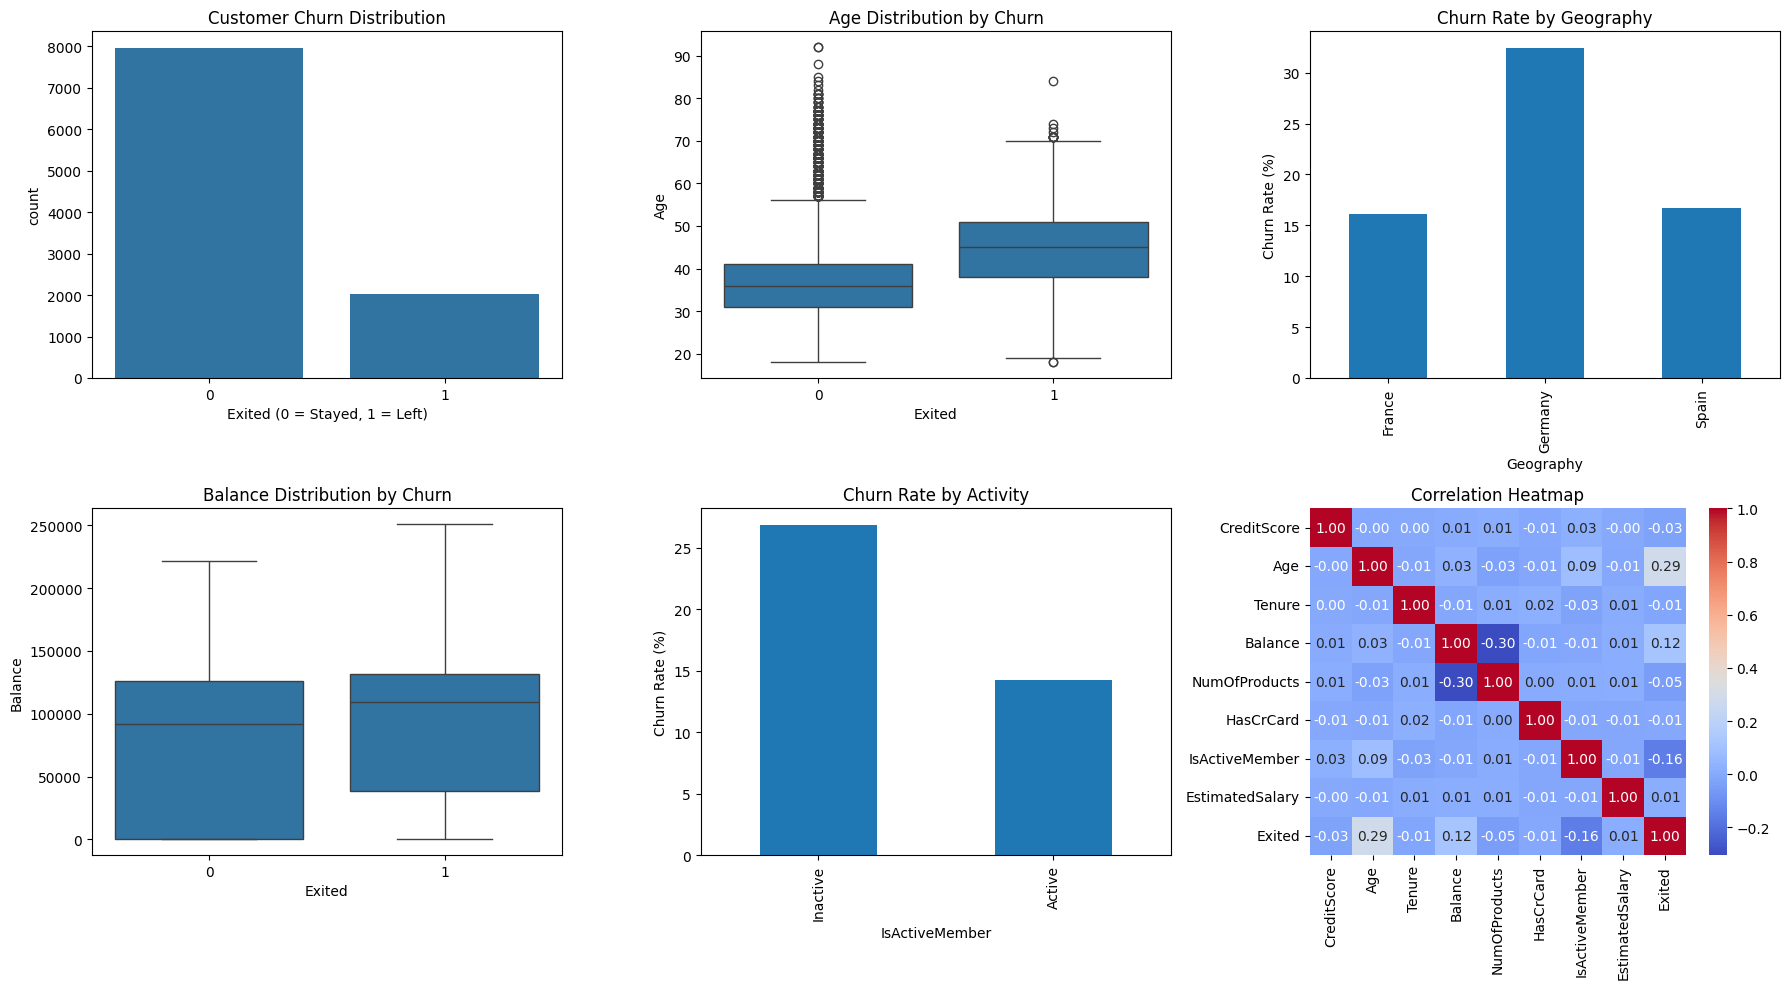

In [ ]:
# EDA VISUALISATIONS

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Customer churn distribution
sns.countplot(data=df, x='Exited', ax=axes[0, 0])
axes[0, 0].set_title('Customer Churn Distribution')
axes[0, 0].set_xlabel('Exited (0 = Stayed, 1 = Left)')

# 2. Age distribution by churn
sns.boxplot(data=df, x='Exited', y='Age', ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution by Churn')

# 3. Churn rate by geography
geo_churn = df.groupby('Geography')['Exited'].mean() * 100
geo_churn.plot(kind='bar', ax=axes[0, 2])
axes[0, 2].set_title('Churn Rate by Geography')
axes[0, 2].set_ylabel('Churn Rate (%)')

# 4. Balance distribution by churn
sns.boxplot(data=df, x='Exited', y='Balance', ax=axes[1, 0])
axes[1, 0].set_title('Balance Distribution by Churn')

# 5. Churn rate by customer activity
activity_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100
activity_churn.plot(kind='bar', ax=axes[1, 1])
axes[1, 1].set_title('Churn Rate by Activity')
axes[1, 1].set_ylabel('Churn Rate (%)')
axes[1, 1].set_xticks([0, 1], ['Inactive', 'Active'])

# 6. Numerical feature correlation
numeric_data = df.select_dtypes(include=np.number).drop(
    columns=['RowNumber', 'CustomerId']
)

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    ax=axes[1, 2]
)
axes[1, 2].set_title('Correlation Heatmap')

plt.tight_layout()
plt.show()

In [ ]:
# EXACT CHURN RATE ANALYSIS

# 1. Churn rate by geography
print("Churn Rate by Geography:")
print(
    df.groupby('Geography')['Exited']
    .mean()
    .mul(100)
    .round(2)
)

# 2. Churn rate by customer activity
print("\nChurn Rate by Activity:")
print(
    df.groupby('IsActiveMember')['Exited']
    .mean()
    .mul(100)
    .round(2)
)

# 3. Churn rate by number of products
print("\nChurn Rate by Number of Products:")
print(
    df.groupby('NumOfProducts')['Exited']
    .mean()
    .mul(100)
    .round(2)
)

# 4. Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 25, 35, 45, 55, 100],
    labels=['18-25', '26-35', '36-45', '46-55', '56+']
)

print("\nChurn Rate by Age Group:")
print(
    df.groupby('AgeGroup', observed=False)['Exited']
    .mean()
    .mul(100)
    .round(2)
)

Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64

Churn Rate by Activity:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64

Churn Rate by Number of Products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64

Churn Rate by Age Group:
AgeGroup
18-25     7.53
26-35     8.50
36-45    19.62
46-55    50.57
56+      36.75
Name: Exited, dtype: float64


In [ ]:
# CUSTOMER COUNTS AND CHURN COUNTS

print("Geography:")
print(pd.crosstab(df['Geography'], df['Exited']))

print("\nNumber of Products:")
print(pd.crosstab(df['NumOfProducts'], df['Exited']))

print("\nAge Groups:")
print(pd.crosstab(df['AgeGroup'], df['Exited']))

print("\nCustomer Activity:")
print(pd.crosstab(df['IsActiveMember'], df['Exited']))

Geography:
Exited        0    1
Geography           
France     4204  810
Germany    1695  814
Spain      2064  413

Number of Products:
Exited            0     1
NumOfProducts            
1              3675  1409
2              4242   348
3                46   220
4                 0    60

Age Groups:
Exited       0    1
AgeGroup           
18-25      565   46
26-35     3241  301
36-45     3003  733
46-55      648  663
56+        506  294

Customer Activity:
Exited             0     1
IsActiveMember            
0               3547  1302
1               4416   735


In [ ]:
# DATA PREPROCESSING

# Remove unnecessary columns
X = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname',
             'Exited', 'AgeGroup']
)

# Target variable
y = df['Exited']

# Check the results
print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Feature dataset shape: (10000, 10)
Target dataset shape: (10000,)

Features:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [ ]:
# Identify numerical and categorical columns

numerical_features = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'HasCrCard',
    'IsActiveMember',
    'EstimatedSalary'
]

categorical_features = [
    'Geography',
    'Gender'
]

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Categorical features: ['Geography', 'Gender']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training features: (8000, 10)
Testing features: (2000, 10)

Training target distribution:
Exited
0    79.625
1    20.375
Name: proportion, dtype: float64

Testing target distribution:
Exited
0    79.65
1    20.35
Name: proportion, dtype: float64


In [ ]:
# DATA PREPROCESSING PIPELINE

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Continuous numerical features
continuous_features = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'NumOfProducts',
    'EstimatedSalary'
]

# Binary numerical features
binary_features = [
    'HasCrCard',
    'IsActiveMember'
]

# Preprocessing for numerical features
numerical_transformer = StandardScaler()

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown='ignore'
)

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, continuous_features),
        ('cat', categorical_transformer, categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
# APPLY PREPROCESSING

X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:",
      X_train_processed.shape)

print("Testing data after preprocessing:",
      X_test_processed.shape)

Training data after preprocessing: (8000, 13)
Testing data after preprocessing: (2000, 13)


In [ ]:
# MACHINE LEARNING MODEL IMPORTS

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [ ]:
# LOGISTIC REGRESSION MODEL

log_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

# Train the model
log_model.fit(X_train_processed, y_train)

# Make predictions
log_predictions = log_model.predict(X_test_processed)

# Get prediction probabilities
log_probabilities = log_model.predict_proba(
    X_test_processed
)[:, 1]

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [ ]:
# RANDOM FOREST MODEL

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train_processed, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test_processed)

# Get prediction probabilities
rf_probabilities = rf_model.predict_proba(
    X_test_processed
)[:, 1]

print("Random Forest training completed!")

Random Forest training completed!


In [ ]:
# MODEL EVALUATION

def evaluate_model(name, actual, predictions, probabilities):

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print("Accuracy:",
          round(accuracy_score(actual, predictions), 4))

    print("Precision:",
          round(precision_score(actual, predictions, zero_division=0), 4))

    print("Recall:",
          round(recall_score(actual, predictions, zero_division=0), 4))

    print("F1 Score:",
          round(f1_score(actual, predictions, zero_division=0), 4))

    print("ROC-AUC:",
          round(roc_auc_score(actual, probabilities), 4))

    print("\nConfusion Matrix:")
    print(confusion_matrix(actual, predictions))

    print("\nClassification Report:")
    print(classification_report(actual, predictions, zero_division=0))


# Evaluate Logistic Regression
evaluate_model(
    "LOGISTIC REGRESSION",
    y_test,
    log_predictions,
    log_probabilities
)

# Evaluate Random Forest
evaluate_model(
    "RANDOM FOREST",
    y_test,
    rf_predictions,
    rf_probabilities
)


LOGISTIC REGRESSION
Accuracy: 0.7135
Precision: 0.3872
Recall: 0.7002
F1 Score: 0.4987
ROC-AUC: 0.7772

Confusion Matrix:
[[1142  451]
 [ 122  285]]

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1593
           1       0.39      0.70      0.50       407

    accuracy                           0.71      2000
   macro avg       0.65      0.71      0.65      2000
weighted avg       0.80      0.71      0.74      2000


RANDOM FOREST
Accuracy: 0.8575
Precision: 0.7629
Recall: 0.4349
F1 Score: 0.554
ROC-AUC: 0.8525

Confusion Matrix:
[[1538   55]
 [ 230  177]]

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.76      0.43      0.55       407

    accuracy                           0.86      2000
   macro avg       0.82      0.70      0.73      2000
weighted avg       0.85      0.86      0.84      2000



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Split existing training data into training and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a fresh preprocessing pipeline
validation_preprocessor = clone(preprocessor)

X_subtrain_processed = validation_preprocessor.fit_transform(
    X_subtrain
)

X_val_processed = validation_preprocessor.transform(X_val)

# Train Random Forest using only the sub-training data
validation_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

validation_rf.fit(X_subtrain_processed, y_subtrain)

# Get churn probabilities for validation data
val_probabilities = validation_rf.predict_proba(
    X_val_processed
)[:, 1]

# Compare different classification thresholds
print("THRESHOLD COMPARISON")

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Precision:",
          round(precision_score(y_val, predictions), 4))

    print("Recall:",
          round(recall_score(y_val, predictions), 4))

    print("F1-score:",
          round(f1_score(y_val, predictions), 4))

THRESHOLD COMPARISON

Threshold: 0.3
Precision: 0.5926
Recall: 0.638
F1-score: 0.6145

Threshold: 0.35
Precision: 0.6419
Recall: 0.5828
F1-score: 0.6109

Threshold: 0.4
Precision: 0.6911
Recall: 0.5215
F1-score: 0.5944

Threshold: 0.45
Precision: 0.7438
Recall: 0.4632
F1-score: 0.5709

Threshold: 0.5
Precision: 0.7816
Recall: 0.4172
F1-score: 0.544

Threshold: 0.55
Precision: 0.8264
Recall: 0.365
F1-score: 0.5064


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

# Split the original training data
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Create a separate preprocessing pipeline
validation_preprocessor = clone(preprocessor)

X_subtrain_processed = validation_preprocessor.fit_transform(X_subtrain)
X_val_processed = validation_preprocessor.transform(X_val)

# Train Random Forest using the smaller training set
validation_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

validation_rf.fit(X_subtrain_processed, y_subtrain)

# Get churn probabilities
val_probabilities = validation_rf.predict_proba(X_val_processed)[:, 1]

# Compare different thresholds
print("=============================================")
print("THRESHOLD COMPARISON")
print("=============================================")

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55]:

    predictions = (val_probabilities >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_val, predictions), 4))
    print("Recall:", round(recall_score(y_val, predictions), 4))
    print("F1-score:", round(f1_score(y_val, predictions), 4))


THRESHOLD COMPARISON

Threshold: 0.3
Precision: 0.5926
Recall: 0.638
F1-score: 0.6145

Threshold: 0.35
Precision: 0.6419
Recall: 0.5828
F1-score: 0.6109

Threshold: 0.4
Precision: 0.6911
Recall: 0.5215
F1-score: 0.5944

Threshold: 0.45
Precision: 0.7438
Recall: 0.4632
F1-score: 0.5709

Threshold: 0.5
Precision: 0.7816
Recall: 0.4172
F1-score: 0.544

Threshold: 0.55
Precision: 0.8264
Recall: 0.365
F1-score: 0.5064


In [ ]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# 1. Prepare the final preprocessing pipeline
final_preprocessor = clone(preprocessor)

X_train_final = final_preprocessor.fit_transform(X_train)
X_test_final = final_preprocessor.transform(X_test)

# 2. Train the final Random Forest model
final_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

final_rf.fit(X_train_final, y_train)

# 3. Get churn probabilities
final_probabilities = final_rf.predict_proba(X_test_final)[:, 1]

# 4. Apply the selected threshold
selected_threshold = 0.30

final_predictions = (
    final_probabilities >= selected_threshold
).astype(int)

# 5. Evaluate the final model
print("=============================================")
print("FINAL RANDOM FOREST MODEL")
print("=============================================")

print("Selected Threshold:", selected_threshold)

print("Accuracy:",
      round(accuracy_score(y_test, final_predictions), 4))

print("Precision:",
      round(precision_score(y_test, final_predictions), 4))

print("Recall:",
      round(recall_score(y_test, final_predictions), 4))

print("F1 Score:",
      round(f1_score(y_test, final_predictions), 4))

print("ROC-AUC:",
      round(roc_auc_score(y_test, final_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_predictions))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))


FINAL RANDOM FOREST MODEL
Selected Threshold: 0.3
Accuracy: 0.833
Precision: 0.5785
Recall: 0.6609
F1 Score: 0.617
ROC-AUC: 0.8525

Confusion Matrix:
[[1397  196]
 [ 138  269]]

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.88      0.89      1593
           1       0.58      0.66      0.62       407

    accuracy                           0.83      2000
   macro avg       0.74      0.77      0.76      2000
weighted avg       0.84      0.83      0.84      2000



RANDOM FOREST FEATURE IMPORTANCE
        Feature  Importance
            Age    0.251936
        Balance    0.141568
EstimatedSalary    0.140305
    CreditScore    0.133861
  NumOfProducts    0.125811
         Tenure    0.082714
      Geography    0.047926
         Gender    0.021189
      HasCrCard    0.000000
 IsActiveMember    0.000000


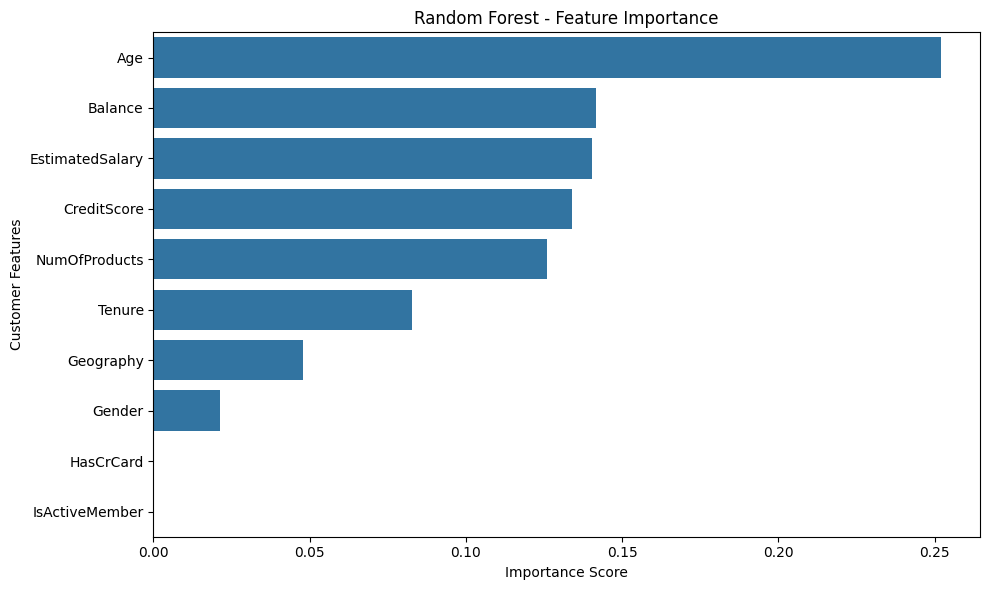

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Get feature names after preprocessing
feature_names = final_preprocessor.get_feature_names_out()

# Get importance values from Random Forest
importance_values = final_rf.feature_importances_

# Create a DataFrame
importance_df = pd.DataFrame({
    'Encoded_Feature': feature_names,
    'Importance': importance_values
})

# Group encoded features under their original feature names
original_features = X_train.columns.tolist()

grouped_importance = []

for feature in original_features:

    matching_rows = importance_df[
        importance_df['Encoded_Feature'].apply(
            lambda name: (
                name == f'num__{feature}'
                or name == f'cat__{feature}'
                or name.startswith(f'cat__{feature}_')
            )
        )
    ]

    grouped_importance.append({
        'Feature': feature,
        'Importance': matching_rows['Importance'].sum()
    })

# Create final feature importance DataFrame
grouped_importance_df = pd.DataFrame(grouped_importance)

# Sort from highest to lowest
grouped_importance_df = grouped_importance_df.sort_values(
    by='Importance',
    ascending=False
)

# Display results
print("=============================================")
print("RANDOM FOREST FEATURE IMPORTANCE")
print("=============================================")

print(grouped_importance_df.to_string(index=False))

# Visualise feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=grouped_importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Customer Features')
plt.tight_layout()
plt.show()


In [ ]:

# OUTLIER DETECTION USING IQR

numerical_columns = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'EstimatedSalary'
]

print("=============================================")
print("OUTLIER DETECTION USING IQR")
print("=============================================")

for column in numerical_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\nFeature: {column}")
    print("Lower Bound:", round(lower_bound, 2))
    print("Upper Bound:", round(upper_bound, 2))
    print("Outlier Count:", len(outliers))
    print("Outlier Percentage:",
          round(len(outliers) / len(df) * 100, 2), "%")

OUTLIER DETECTION USING IQR

Feature: CreditScore
Lower Bound: 383.0
Upper Bound: 919.0
Outlier Count: 15
Outlier Percentage: 0.15 %

Feature: Age
Lower Bound: 14.0
Upper Bound: 62.0
Outlier Count: 359
Outlier Percentage: 3.59 %

Feature: Tenure
Lower Bound: -3.0
Upper Bound: 13.0
Outlier Count: 0
Outlier Percentage: 0.0 %

Feature: Balance
Lower Bound: -191466.36
Upper Bound: 319110.6
Outlier Count: 0
Outlier Percentage: 0.0 %

Feature: EstimatedSalary
Lower Bound: -96577.1
Upper Bound: 296967.45
Outlier Count: 0
Outlier Percentage: 0.0 %


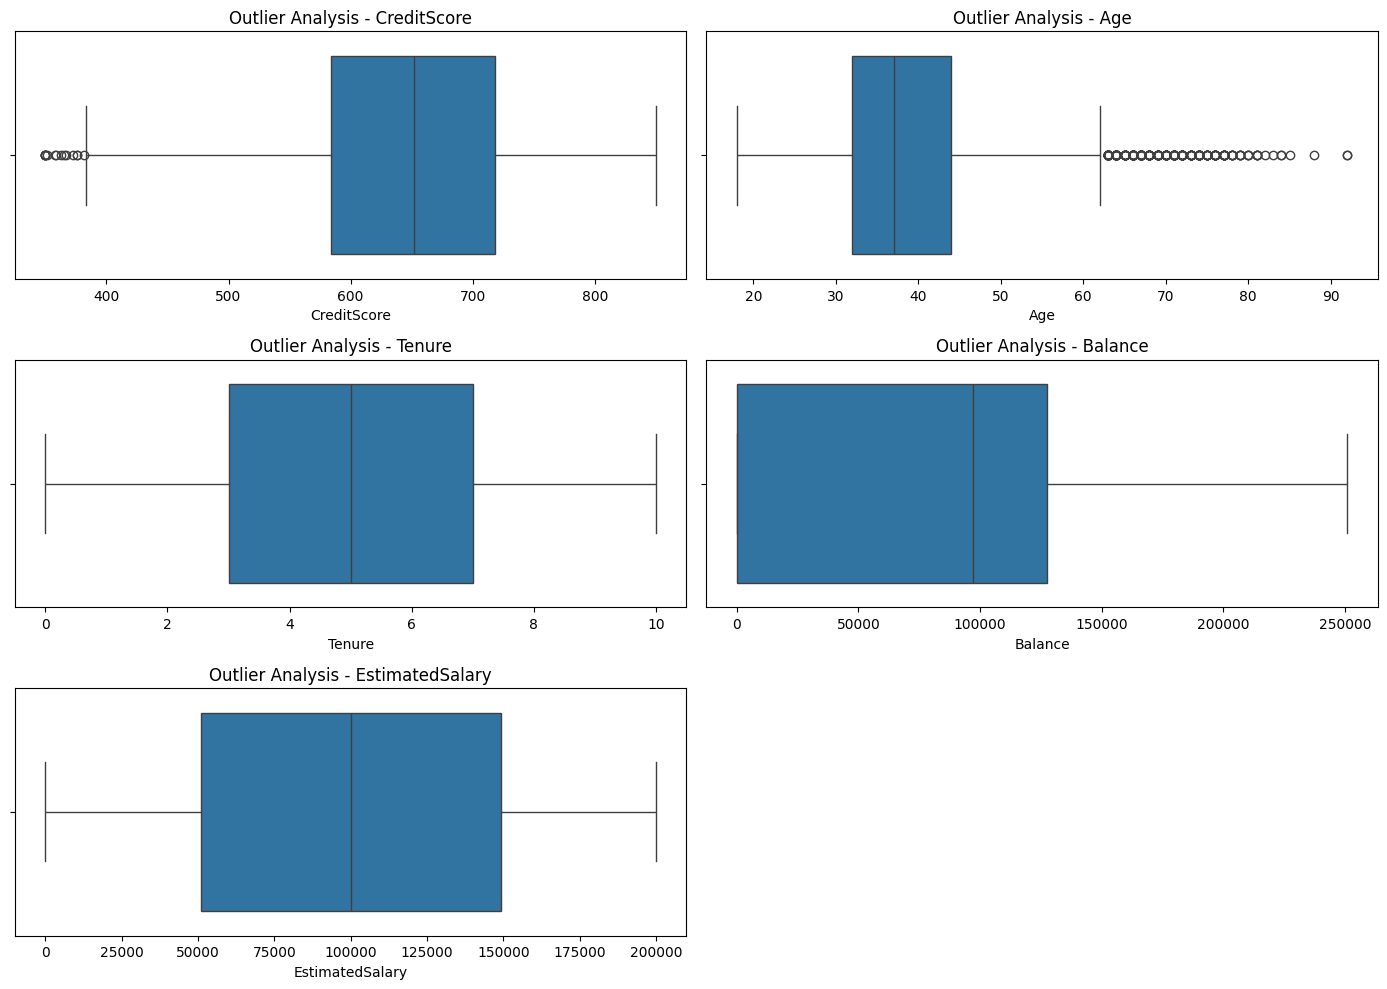

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

numerical_columns = [
    'CreditScore',
    'Age',
    'Tenure',
    'Balance',
    'EstimatedSalary'
]

plt.figure(figsize=(14, 10))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(3, 2, i)

    sns.boxplot(x=df[column])

    plt.title(f'Outlier Analysis - {column}')
    plt.xlabel(column)

plt.tight_layout()
plt.show()
